In [2]:
import numpy as np 
import pandas as pd 

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [20]:
df = sns.load_dataset('titanic')

In [21]:
df = df[['age','fare','survived']]

In [22]:
df

,age,fare,survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1
3,35.0,53.1000,1
4,35.0,8.0500,0
...,...,...,...
886,27.0,13.0000,0
887,19.0,30.0000,1
888,NaN,23.4500,0
889,26.0,30.0000,1


In [23]:
df['age'].fillna(df['age'].mean(),inplace=True)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16272\1492264711.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].mean(),inplace=True)


In [25]:
df.head()

,age,fare,survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1
3,35.0,53.1000,1
4,35.0,8.0500,0


In [28]:
X = df.iloc[:,0:2]
Y = df.iloc[:,-1]

In [42]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16272\4108461556.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['age'])


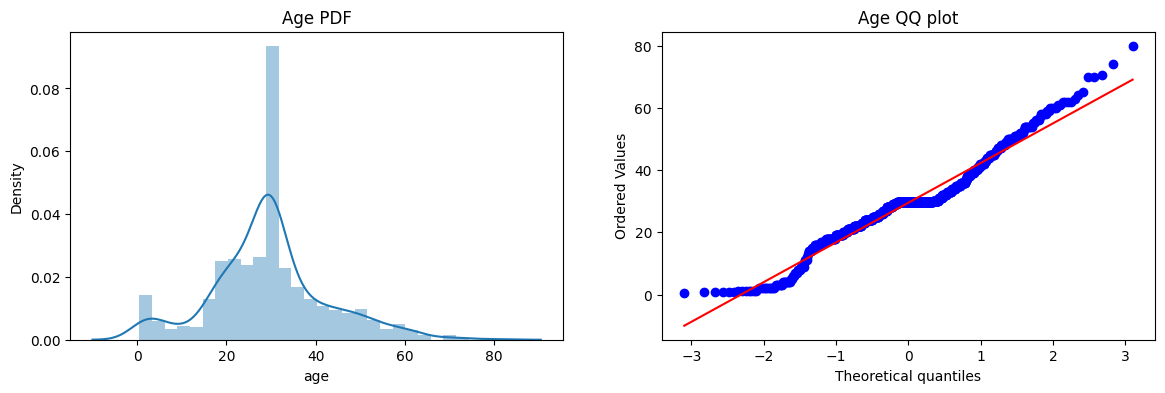

In [35]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(x_train['age'])
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(x_train['age'],dist='norm',plot=plt)
plt.title("Age QQ plot")

plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16272\2043380192.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['fare'])


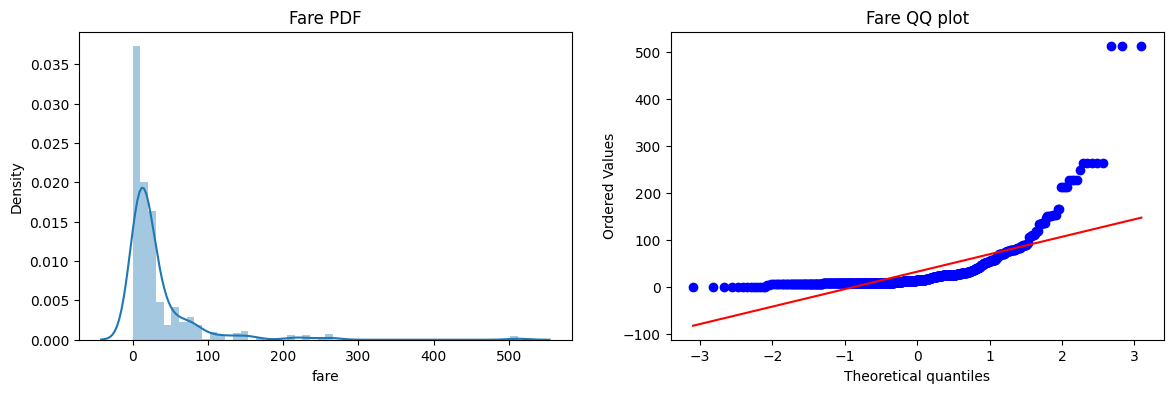

In [36]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(x_train['fare'])
plt.title("Fare PDF")

plt.subplot(122)
stats.probplot(x_train['fare'],dist='norm',plot=plt)
plt.title("Fare QQ plot")

plt.show()

In [37]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [38]:
clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred = clf.predict(x_test)
y_pred2 = clf2.predict(x_test)

print("LR Accuraccy",accuracy_score(y_pred,y_test))
print("DT Accuraccy",accuracy_score(y_pred2,y_test))


LR Accuraccy 0.6480446927374302
DT Accuraccy 0.6536312849162011


In [43]:
trf = FunctionTransformer(func=np.log1p)

In [52]:
x_train_transform = trf.fit_transform(x_train)
x_test_transform = trf.transform(x_test)

In [45]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [57]:
clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred = clf.predict(x_test)
y_pred2 = clf2.predict(x_test_transform)

In [56]:
print("LR Accuraccy: ",accuracy_score(y_pred,y_test))
print("DT Accuraccy: ",accuracy_score(y_pred2,y_test))

LR Accuraccy:  0.6815642458100558
DT Accuraccy:  0.6703910614525139


In [59]:
X_transform = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR : ",np.mean(cross_val_score(clf,X_transform,Y,scoring='accuracy',cv=10)))
print("DT : ",np.mean(cross_val_score(clf2,X_transform,Y,scoring='accuracy',cv=10)))

LR :  0.678027465667915
DT :  0.6644569288389512


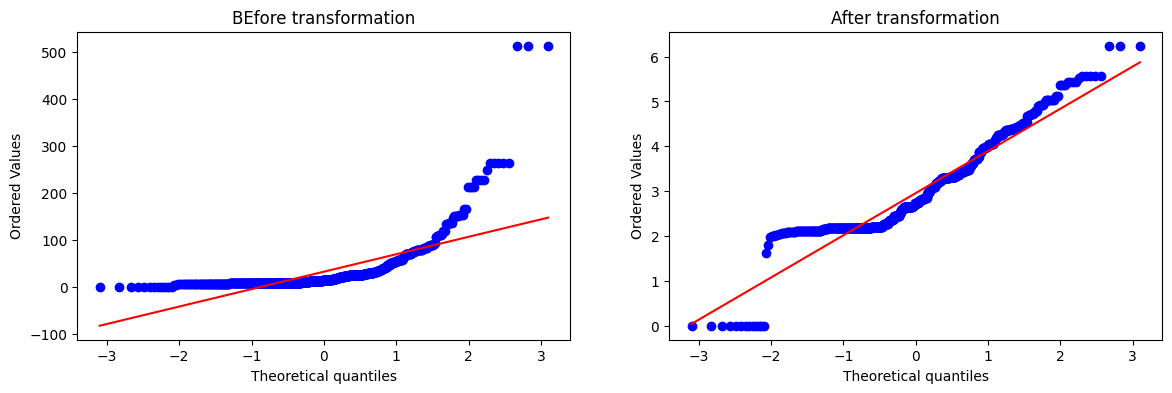

In [60]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(x_train['fare'],dist='norm',plot=plt)
plt.title("BEfore transformation")

plt.subplot(122)
stats.probplot(x_train_transform['fare'],dist='norm',plot=plt)
plt.title("After transformation")

plt.show()